# Project 2: Credit Card Fraud Detection as Anomaly Ranking

**Course:** DSC8307 Data Mining, Modelling and Analytics
**Task:** Build an anomaly detector that prioritises transactions for fraud investigation, then evaluate its ranking against the withheld fraud labels.

**Data source:** `creditcard.csv`, Kaggle *Credit Card Fraud Detection* dataset, collected by Worldline and the Machine Learning Group of ULB (Université Libre de Bruxelles). A. Dal Pozzolo, O. Caelen, R. A. Johnson and G. Bontempi (2015), "Calibrating Probability with Undersampling for Unbalanced Classification", *IEEE Symposium on Computational Intelligence and Data Mining (CIDM)*. European card transactions over two days in September 2013.

**Contents:** 1. Loading and inspecting · 2. Data preparation · 3. Evaluation design · 4. Statistical outlier baseline · 5. Cluster-based approach · 6. Classification-based approaches · 7. Comparison · 8. Sensitivity checks · 9. Why an unusual transaction is not necessarily fraud · 10. Conclusions and limitations · References

**To run:** put `creditcard.csv` (or the four compressed parts `creditcard_part*.csv.gz`) in the same folder as this notebook and install the packages in `requirements.txt`.


## 1. Loading and inspecting the data

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
NORMAL_COLOUR, FRAUD_COLOUR = "steelblue", "darkorange"

# The full file (150 MB) is too large for GitHub, so the repository stores it as four
# compressed parts. The notebook uses creditcard.csv if it is there, otherwise the parts.
if os.path.exists("creditcard.csv"):
    df = pd.read_csv("creditcard.csv")
    print("Loaded creditcard.csv")
else:
    parts = sorted(glob.glob("creditcard_part*.csv.gz"))
    df = pd.concat([pd.read_csv(p) for p in parts], ignore_index=True)
    print("Loaded", len(parts), "compressed parts:", parts)

print(df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Fraudulent transactions:", df["Class"].sum(), " share (%):", round(100 * df["Class"].mean(), 3))
print("Time span (hours):", round(df["Time"].max() / 3600, 1))

Loaded creditcard.csv
(284807, 31)
Missing values: 0
Duplicate rows: 1081
Fraudulent transactions: 492  share (%): 0.173
Time span (hours): 48.0


**Observations:**

- 284,807 transactions and 31 columns: `Time`, `Amount`, 28 anonymised features `V1`–`V28` and the label `Class` (1 = fraud)
- no missing values
- **492 frauds (0.173%)**: extremely imbalanced. A model that calls everything "normal" would be 99.83% accurate and useless, so accuracy is not used anywhere in this analysis
- **1,081 exact duplicate rows**
- `Time` covers 48 hours and counts seconds since the first transaction, not clock time

In [2]:
V_COLS = [f"V{i}" for i in range(1, 29)]
print("Transactions with Amount = 0:", (df["Amount"] == 0).sum())
amount_summary = df.groupby(df["Class"].map({0: "Normal", 1: "Fraud"}))["Amount"].describe()
amount_summary[["count", "mean", "50%", "75%", "max"]].rename(columns={"50%": "median"}).round(2)

Transactions with Amount = 0: 1825


,count,mean,median,75%,max
Class,,,,,
Fraud,492.0,122.21,9.25,105.89,2125.87
Normal,284315.0,88.29,22.00,77.05,25691.16


In [3]:
from scipy.stats import kurtosis

v_stats = pd.DataFrame({"std": df[V_COLS].std(),
                        "kurtosis (normal = 0)": kurtosis(df[V_COLS])})
print("Largest absolute correlation between two different V columns:",
      round(np.abs(np.corrcoef(df[V_COLS].values.T) - np.eye(28)).max(), 3))
print("Columns most correlated with Amount:")
print(df[V_COLS].corrwith(df["Amount"]).abs().sort_values(ascending=False).head(3).round(2))
v_stats.T.round(1)

Largest absolute correlation between two different V columns: 0.0
Columns most correlated with Amount:
V2    0.53
V7    0.40
V5    0.39
dtype: float64


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
std,2.0,1.7,1.5,1.4,1.4,1.3,1.2,1.2,1.1,1.1,...,0.8,0.8,0.7,0.7,0.6,0.6,0.5,0.5,0.4,0.3
kurtosis (normal = 0),32.5,95.8,26.6,2.6,206.9,42.6,405.6,220.6,3.7,32.0,...,1.7,271.0,207.3,2.8,440.1,0.6,4.3,0.9,245.0,933.4


**Observations on the features:**

- **V1–V28 are principal components** produced by the data provider to protect confidentiality. They are centred on zero, perfectly uncorrelated with each other (largest correlation 0.0), and ordered by decreasing variance (standard deviation from 2.0 for V1 down to 0.3 for V28). Their real-world meaning is unknown
- many have **very heavy tails** (kurtosis up to about 930, where a normal distribution has 0). Extreme values are far more common than a bell curve would predict, which matters for the statistical baseline in Section 4
- `Amount` was not transformed and is correlated with some components (V2: 0.53)
- **frauds are typically small:** median 9.25 EUR against 22 EUR for normal transactions, although fraud amounts reach 2,126 EUR. The largest transactions (up to 25,691 EUR) are all normal. 1,825 transactions have an amount of 0

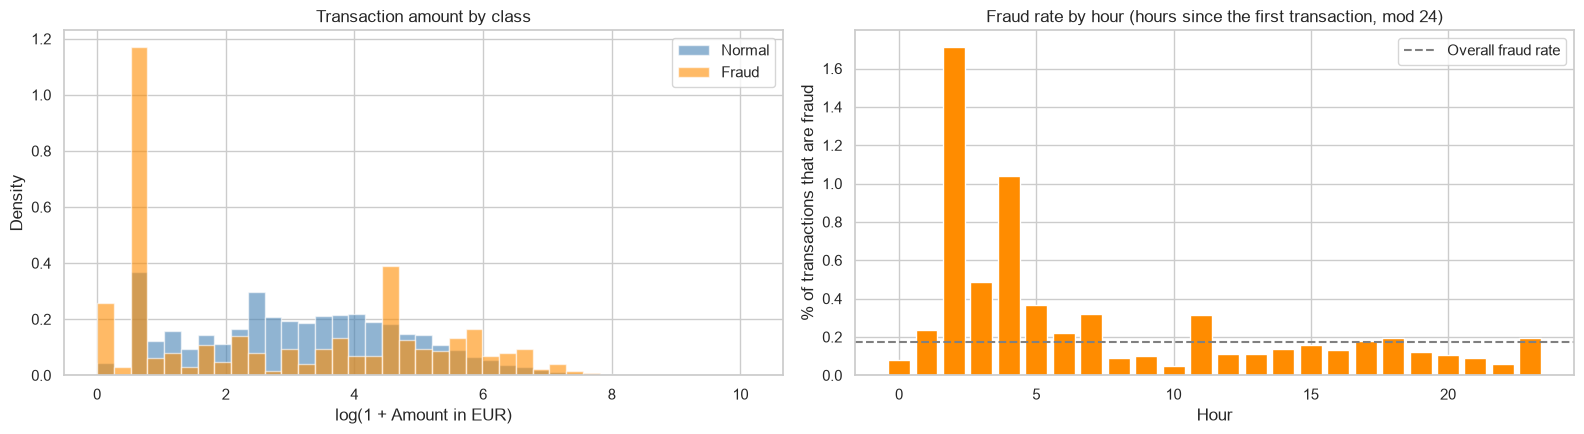

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
bins = np.linspace(0, np.log1p(df["Amount"].max()), 40)
for cls, colour, name in [(0, NORMAL_COLOUR, "Normal"), (1, FRAUD_COLOUR, "Fraud")]:
    axes[0].hist(np.log1p(df.loc[df["Class"] == cls, "Amount"]), bins=bins, density=True,
                 alpha=0.6, color=colour, label=name)
axes[0].set(title="Transaction amount by class", xlabel="log(1 + Amount in EUR)", ylabel="Density")
axes[0].legend()

hour = (df["Time"] // 3600) % 24
rate = df.groupby(hour)["Class"].mean() * 100
axes[1].bar(rate.index, rate.values, color=FRAUD_COLOUR, edgecolor="white")
axes[1].axhline(df["Class"].mean() * 100, color="grey", linestyle="--", label="Overall fraud rate")
axes[1].set(title="Fraud rate by hour (hours since the first transaction, mod 24)",
            xlabel="Hour", ylabel="% of transactions that are fraud")
axes[1].legend()
plt.tight_layout()
plt.show()

Features that separate fraud most: ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']


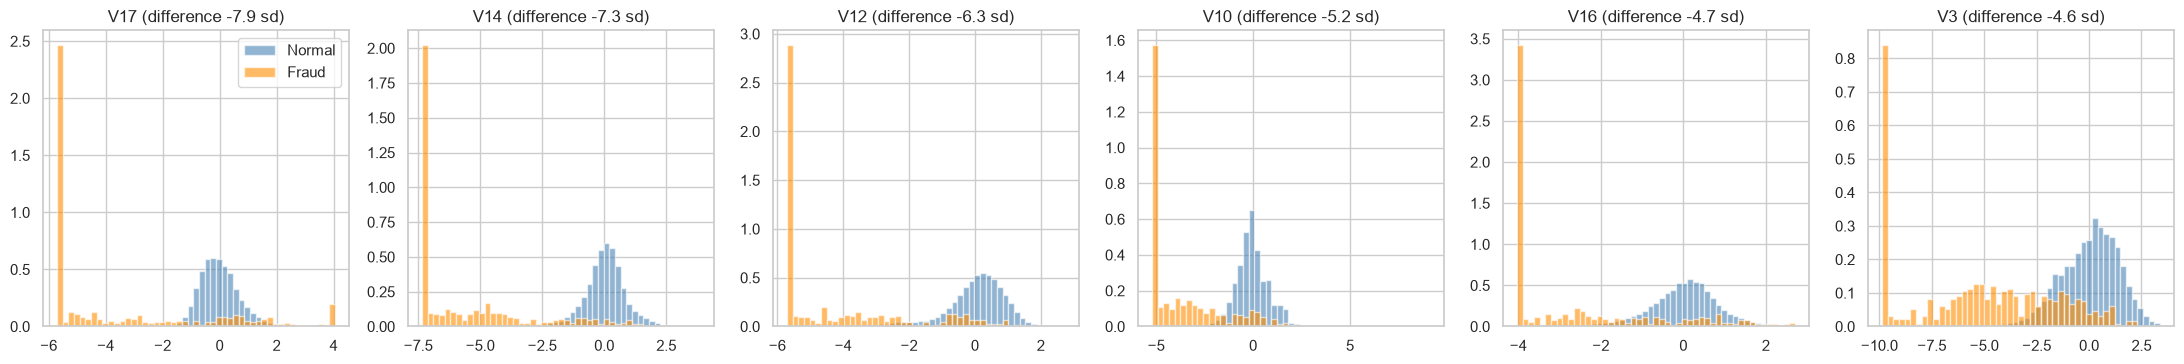

In [5]:
# How different are fraud and normal transactions on each V feature?
# Standardised mean difference = (fraud mean - normal mean) / overall std
smd = ((df.loc[df["Class"] == 1, V_COLS].mean() - df.loc[df["Class"] == 0, V_COLS].mean())
       / df[V_COLS].std()).sort_values(key=np.abs, ascending=False)
top = smd.index[:6].tolist()
print("Features that separate fraud most:", top)

fig, axes = plt.subplots(1, 6, figsize=(22, 3.8))
for ax, col in zip(axes, top):
    lo, hi = df[col].quantile([0.001, 0.999])
    b = np.linspace(lo, hi, 50)
    ax.hist(df.loc[df["Class"] == 0, col].clip(lo, hi), bins=b, density=True, alpha=0.6,
            color=NORMAL_COLOUR, label="Normal")
    ax.hist(df.loc[df["Class"] == 1, col].clip(lo, hi), bins=b, density=True, alpha=0.6,
            color=FRAUD_COLOUR, label="Fraud")
    ax.set_title(f"{col} (difference {smd[col]:.1f} sd)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Observations:**

- **Amount:** fraud has a spike at very small amounts (about 1 EUR, the tall bar near log 0.7), consistent with "card testing", where a stolen card is tried with a tiny purchase first. Otherwise fraud and normal amounts overlap heavily
- **Time:** the fraud *rate* is highest in hours 2 and 4 (about 1.7% and 1.0%), when few transactions happen overall. Because `Time` starts at the first transaction, the true time of day is unknown
- **V features:** a few components separate fraud strongly. V17, V14, V12 and V10 have fraud means 5–8 standard deviations *below* the normal mean (V17: −7.9, V14: −7.3, V12: −6.3, V10: −5.2). Fraud is therefore visibly *different*, which an anomaly detector can exploit

**Limitations of the data:**

- only 2 days of data, from 2013
- anonymised PCA features cannot be interpreted or checked for bias
- there is no customer identifier, so behaviour cannot be compared with a customer's own history
- labels record frauds that were *detected*; undetected fraud would appear as "normal"

## 2. Data preparation

- **Duplicates:** the 1,081 duplicate rows (19 of them frauds) are removed, leaving 283,726 rows and 473 frauds. Identical rows can land on both sides of a split and make scores look better than they really are. Some may be genuine repeated charges, but they cannot be told apart, so this is noted as a limitation.
- **`Amount`:** transformed to `log(1 + Amount)`. It is highly right-skewed, so without the log a few very large purchases would dominate every distance-based score. The +1 handles zero amounts.
- **`Time`:** not used as a feature, only to order and split the data. Raw seconds since the start would not carry over to future days, and with only 2 days each hour of the day is seen at most twice, too little to learn a reliable time-of-day effect.
- **V1–V28:** kept as they are, since they are already centred, uncorrelated principal components.
- **Scaling:** all 29 features are standardised using means and standard deviations from the **training period only**. Distance-based methods (Mahalanobis, k-means, SVM) need features on comparable scales, and fitting on training data only means no information leaks from the test period.
- **Labels:** `Class` is **withheld** from all unsupervised methods and used only to evaluate them. The supervised classifier uses labels from the training period only. This matches the task: build a detector, then check its ranking against the fraud labels.
- **Split:** time-ordered. The first 60% of the period (hours 0–33.4) is used for learning and the last 40% (hours 33.4–48) for evaluation. A bank would learn from the past and score new transactions, so this is more realistic than a random split. Section 8 also checks a random split.

In [6]:
from sklearn.preprocessing import StandardScaler

data = df.drop_duplicates().sort_values("Time", kind="stable").reset_index(drop=True)
data["log_amount"] = np.log1p(data["Amount"])
FEATURES = V_COLS + ["log_amount"]
print("Rows after removing duplicates:", len(data), " Frauds:", data["Class"].sum())

# Time-ordered split: learn from the first 60% of the period, evaluate on the last 40%
cut = data["Time"].quantile(0.60)
train, test = data[data["Time"] < cut], data[data["Time"] >= cut]
print("Training period: hours 0 -", round(cut / 3600, 1), " Transactions:", len(train), " Frauds:", train["Class"].sum())
print("Test period: hours", round(cut / 3600, 1), "- 48.0", " Transactions:", len(test), " Frauds:", test["Class"].sum())

scaler = StandardScaler().fit(train[FEATURES])          # fitted on the training period only
X_train, X_test = scaler.transform(train[FEATURES]), scaler.transform(test[FEATURES])
y_train, y_test = train["Class"].values, test["Class"].values   # y_test is used ONLY for evaluation

Rows after removing duplicates: 283726  Frauds: 473
Training period: hours 0 - 33.4  Transactions: 170235  Frauds: 342
Test period: hours 33.4 - 48.0  Transactions: 113491  Frauds: 131


## 3. Evaluation design

Each approach gives every test transaction an **anomaly score**. Investigators would review transactions from the highest score downwards, so we evaluate the **ranking**:

- **PR-AUC (average precision):** the main metric. It summarises precision across all recall levels and focuses on the rare fraud class. A random ranking scores about the fraud rate (0.0012). It is more informative than ROC-AUC when positives are this rare (Saito & Rehmsmeier, 2015)
- **ROC-AUC:** reported for completeness. With 99.9% normal transactions it can look excellent even when the top of the ranking is poor (Section 7 shows this happening)
- **Frauds in the top 100 / 500 / 1,000:** directly answers "if investigators can review N transactions, how many frauds do they find?"
- **95% bootstrap interval for PR-AUC:** the test period contains only 131 frauds, so results carry real uncertainty

In [7]:
from sklearn.metrics import average_precision_score, roc_auc_score

BUDGETS = [100, 500, 1000]     # number of top-ranked transactions investigators could review

def evaluate(scores, y=None):
    """Ranking quality of an anomaly score (higher score = more suspicious)."""
    if y is None:
        y = y_test
    order = np.argsort(-scores)                  # most suspicious first
    row = {"PR-AUC (avg precision)": average_precision_score(y, scores),
           "ROC-AUC": roc_auc_score(y, scores)}
    for b in BUDGETS:
        row[f"Frauds in top {b}"] = int(y[order[:b]].sum())
    row["Recall in top 1000"] = y[order[:1000]].sum() / y.sum()
    return row

def bootstrap_ap(scores, y=None, repeats=200, seed=RANDOM_STATE):
    """95% interval for PR-AUC by resampling test transactions."""
    if y is None:
        y = y_test
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(repeats):
        idx = rng.integers(0, len(y), len(y))
        vals.append(average_precision_score(y[idx], scores[idx]))
    return np.percentile(vals, [2.5, 97.5])

scores = {}     # test-period scores of every approach, for the final comparison
rng = np.random.default_rng(RANDOM_STATE)
scores["Random ranking (reference)"] = rng.random(len(y_test))
print("Fraud rate in test period:", round(y_test.mean(), 5), "(the PR-AUC of a random ranking is about this value)")

Fraud rate in test period: 0.00115 (the PR-AUC of a random ranking is about this value)


## 4. Statistical outlier baseline: Mahalanobis distance

A classic statistical outlier test (Han, Kamber & Pei, 2012) models normal data as one multivariate distribution and flags points that are far from its centre. The **Mahalanobis distance** (Mahalanobis, 1936) measures that distance while accounting for the scale and correlation of each feature. If the data were multivariate normal, its square would follow a chi-square distribution with 29 degrees of freedom, which gives a formal cut-off.

It uses no labels and no tuning, so it is a fair baseline that more complex methods must beat.

In [8]:
from scipy.stats import chi2
from sklearn.covariance import EmpiricalCovariance

# Mahalanobis distance of each transaction from the centre of the training data
cov = EmpiricalCovariance().fit(X_train)
d2_train = cov.mahalanobis(X_train)          # squared Mahalanobis distance
d2_test = cov.mahalanobis(X_test)
scores["Statistical baseline (Mahalanobis)"] = d2_test

# If the data were multivariate normal, d2 would follow a chi-square distribution with 29 df
threshold = chi2.ppf(0.999, df=len(FEATURES))
print("Chi-square cut-off for p < 0.001:", round(threshold, 1))
print("Expected share flagged if data were normal: 0.1%   Actual share in training data:",
      round(100 * (d2_train > threshold).mean(), 1), "%")
print("Classic '3-sigma' rule (any |z| > 3) flags", round(100 * (np.abs(X_train) > 3).any(axis=1).mean(), 1),
      "% of training transactions")

flag = d2_test > threshold
print("\nTest period, chi-square rule:", flag.sum(), "flagged,", y_test[flag].sum(), "of", y_test.sum(),
      "frauds caught, precision", round(y_test[flag].mean(), 3))
pd.Series(evaluate(d2_test)).round(3)

Chi-square cut-off for p < 0.001: 58.3
Expected share flagged if data were normal: 0.1%   Actual share in training data: 5.1 %
Classic '3-sigma' rule (any |z| > 3) flags 12.3 % of training transactions

Test period, chi-square rule: 7196 flagged, 113 of 131 frauds caught, precision 0.016


PR-AUC (avg precision)     0.028
ROC-AUC                    0.949
Frauds in top 100          0.000
Frauds in top 500          6.000
Frauds in top 1000        27.000
Recall in top 1000         0.206
dtype: float64

**Baseline results:**

- **the normality assumption fails.** At p < 0.001 the chi-square rule should flag 0.1% of transactions, but it flags 5.1%. The classic "3-sigma" rule flags 12.3%. This is a direct consequence of the heavy tails found in Section 1, so the p-value cut-off cannot be trusted. We use the distance as a **ranking** instead
- as a fixed rule in the test period, the chi-square cut-off flags 7,196 transactions and catches 113 of the 131 frauds (86% recall), but only 1.6% of flagged transactions are fraud (precision 0.016). That is far too many alerts per fraud found
- as a ranking: **PR-AUC 0.028**, about 24 times better than random (0.0012), and ROC-AUC 0.949. But the **top 100 most unusual transactions contain no fraud at all**, and the top 1,000 contain only 27

## 5. Cluster-based approach: distance to the nearest k-means centre

**Idea** (He, Xu & Deng, 2003): normal transactions fall into a few typical patterns (clusters). A transaction that is far from every cluster centre does not fit any normal pattern and is suspicious.

**Why k-means:**

- it scales to 170,000 training transactions. DBSCAN and hierarchical clustering need pairwise distances, which is about 29 billion pairs here and impractical
- unlike the single-centre baseline, it allows normal behaviour to have several "typical" patterns
- the score (distance to the nearest centre) is easy to explain

**Choosing k without labels:** labels are withheld, so k is chosen by the silhouette score on a 10,000-transaction sample of the training data, never by fraud performance.

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Choose k without using the fraud labels: silhouette on a random sample of training transactions
sample = np.random.default_rng(RANDOM_STATE).choice(len(X_train), 10000, replace=False)
k_rows = []
for k in [2, 3, 4, 5, 8, 10, 15, 20]:
    km = KMeans(n_clusters=k, n_init=3, random_state=RANDOM_STATE).fit(X_train)
    k_rows.append({"k": k, "Inertia (millions)": km.inertia_ / 1e6,
                   "Silhouette (10k sample)": silhouette_score(X_train[sample], km.labels_[sample]),
                   "Smallest cluster %": 100 * np.bincount(km.labels_).min() / len(X_train)})
k_table = pd.DataFrame(k_rows).set_index("k")
k_table.round(3)

,Inertia (millions),Silhouette (10k sample),Smallest cluster %
k,,,
2,4.754,0.052,44.801
3,4.530,0.098,11.862
4,4.387,0.074,11.854
5,4.272,0.072,1.181
8,3.988,0.044,0.473
10,3.785,0.066,0.503
15,3.316,0.076,0.126
20,3.076,0.084,0.125


In [10]:
K = int(k_table["Silhouette (10k sample)"].idxmax())
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_train)
print("Chosen k:", K, " cluster sizes (training):", np.bincount(kmeans.labels_))

# Anomaly score: distance to the nearest cluster centre
scores["Cluster-based (k-means distance)"] = kmeans.transform(X_test).min(axis=1)
pd.Series(evaluate(scores["Cluster-based (k-means distance)"])).round(3)

Chosen k: 3  cluster sizes (training): [ 21341 128700  20194]


PR-AUC (avg precision)     0.032
ROC-AUC                    0.950
Frauds in top 100          0.000
Frauds in top 500          9.000
Frauds in top 1000        49.000
Recall in top 1000         0.374
dtype: float64

**Results:**

- silhouette scores are very low for every k (0.04–0.10), so normal transactions have **weak cluster structure**. This limits what a cluster-based method can add. The highest silhouette is at **k = 3** (0.098), which is used. Its clusters hold 21,341 / 128,700 / 20,194 training transactions
- ranking quality: **PR-AUC 0.032**, slightly better than the baseline (0.028), and 49 frauds in the top 1,000 against 27 for the baseline. The top 100 still contains no fraud
- having three centres instead of one helps a little, because some legitimate transactions that are unusual overall are close to one of the secondary patterns

## 6. Classification-based approaches

Classification-based outlier detection trains a model that separates normal from abnormal. There are two kinds, and we use one of each:

**(a) One-class classifier, trained on normal transactions only.** A one-class SVM (Schölkopf et al., 2001) learns a boundary around normal behaviour; anything outside the boundary is anomalous.
- *Why:* it needs no fraud examples, only transactions known to be normal, so it can in principle detect fraud types never seen before. This makes it closest to the task's "anomaly detector"
- an approximation of the RBF kernel (Nyström method; Williams & Seeger, 2001) with a stochastic-gradient solver makes it feasible on about 170,000 rows; an exact one-class SVM scales roughly with the square of the data size
- `nu = 0.01` (expected share of outliers in training data) and `gamma = 0.03` (kernel width) are reasonable defaults; Section 8 varies gamma

**(b) Supervised two-class classifier (logistic regression), trained on the labelled training period.**
- *Why:* in practice banks *do* have historical fraud labels from investigations and chargebacks. A supervised model learns what fraud specifically looks like, rather than merely what is unusual
- logistic regression is fast, interpretable and gives well-ordered scores. Section 1 showed fraud differs strongly along a few components (V14, V17, V12, V10), which a linear model can capture
- `class_weight="balanced"` compensates for the 1:500 imbalance by weighting each fraud more heavily during training
- it represents what labelled history adds on top of pure anomaly detection; the test-period labels are still withheld until evaluation

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM

# One-class classifier: learns the boundary of normal training transactions only.
# Nystroem approximates an RBF kernel so the one-class SVM can handle about 170,000 rows.
ocsvm = make_pipeline(Nystroem(gamma=0.03, n_components=300, random_state=RANDOM_STATE),
                      SGDOneClassSVM(nu=0.01, random_state=RANDOM_STATE))
ocsvm.fit(X_train[y_train == 0])
scores["Classification: one-class SVM (normal-only)"] = -ocsvm.decision_function(X_test)   # minus, so higher = more unusual
pd.Series(evaluate(scores["Classification: one-class SVM (normal-only)"])).round(3)

PR-AUC (avg precision)     0.052
ROC-AUC                    0.943
Frauds in top 100          0.000
Frauds in top 500         33.000
Frauds in top 1000        75.000
Recall in top 1000         0.573
dtype: float64

In [12]:
from sklearn.linear_model import LogisticRegression

# Two-class classifier trained on the labelled history of the training period.
# class_weight="balanced" gives the 342 frauds as much total weight as the ~170,000 normal rows.
logreg = LogisticRegression(max_iter=2000, class_weight="balanced")
logreg.fit(X_train, y_train)
scores["Classification: logistic regression (supervised)"] = logreg.predict_proba(X_test)[:, 1]
pd.Series(evaluate(scores["Classification: logistic regression (supervised)"])).round(3)

PR-AUC (avg precision)      0.740
ROC-AUC                     0.976
Frauds in top 100          88.000
Frauds in top 500         109.000
Frauds in top 1000        112.000
Recall in top 1000          0.855
dtype: float64

**Results:**

- **One-class SVM:** PR-AUC 0.052 and 75 frauds in the top 1,000, the best of the label-free methods (about 1.6 times the cluster-based PR-AUC). It still finds no fraud in the top 100
- **Supervised logistic regression:** PR-AUC **0.740**, with **88 frauds in the top 100** (88% of investigated transactions are fraud) and 109 of the 131 frauds (83%) in the top 500

## 7. Comparison of all approaches (test period)

In [13]:
rows = []
for name, s in scores.items():
    lo, hi = bootstrap_ap(s)
    rows.append({"Approach": name, **evaluate(s), "PR-AUC 95% interval": str(round(lo, 3)) + " - " + str(round(hi, 3))})
results = pd.DataFrame(rows).set_index("Approach")
results.round(3)

,PR-AUC (avg precision),ROC-AUC,Frauds in top 100,Frauds in top 500,Frauds in top 1000,Recall in top 1000,PR-AUC 95% interval
Approach,,,,,,,
Random ranking (reference),0.001,0.509,0,0,2,0.015,0.001 - 0.002
Statistical baseline (Mahalanobis),0.028,0.949,0,6,27,0.206,0.022 - 0.035
Cluster-based (k-means distance),0.032,0.950,0,9,49,0.374,0.026 - 0.041
Classification: one-class SVM (normal-only),0.052,0.943,0,33,75,0.573,0.041 - 0.064
Classification: logistic regression (supervised),0.740,0.976,88,109,112,0.855,0.658 - 0.818


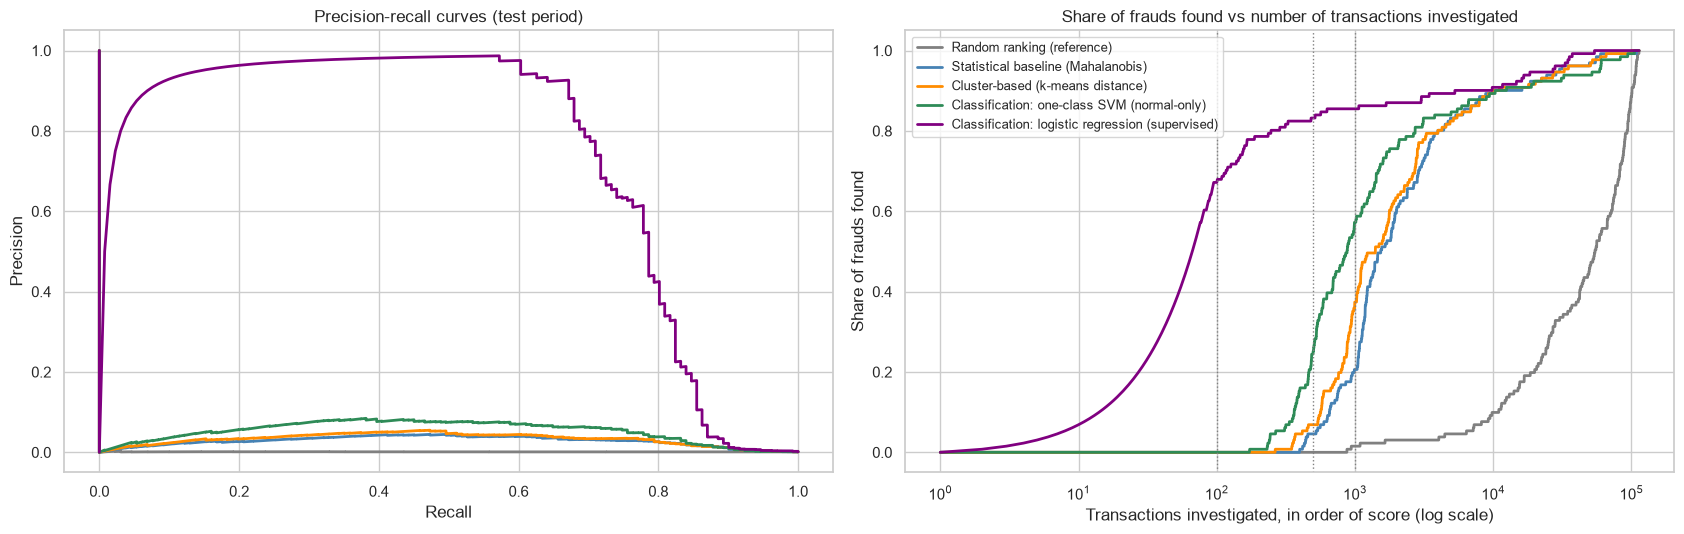

In [14]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
palette = {"Random ranking (reference)": "grey",
           "Statistical baseline (Mahalanobis)": "steelblue",
           "Cluster-based (k-means distance)": "darkorange",
           "Classification: one-class SVM (normal-only)": "seagreen",
           "Classification: logistic regression (supervised)": "purple"}
n_total, n_fraud = len(y_test), y_test.sum()
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    axes[0].plot(r, p, color=palette[name], lw=2, label=name)
    caught = np.cumsum(y_test[np.argsort(-s)]) / n_fraud      # share of frauds found as we go down the ranking
    axes[1].plot(np.arange(1, n_total + 1), caught, color=palette[name], lw=2, label=name)
axes[0].set(title="Precision-recall curves (test period)", xlabel="Recall", ylabel="Precision")
axes[1].set_xscale("log")
for b in BUDGETS:
    axes[1].axvline(b, color="grey", linestyle=":", lw=1)
axes[1].set(title="Share of frauds found vs number of transactions investigated",
            xlabel="Transactions investigated, in order of score (log scale)", ylabel="Share of frauds found")
axes[1].legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

**Interpretation:**

| Approach | Labels needed | PR-AUC (95% interval) | Frauds in top 100 / 500 / 1,000 |
|---|---|---|---|
| Random ranking | – | 0.001 | 0 / 0 / 2 |
| Statistical baseline (Mahalanobis) | None | 0.028 (0.022–0.035) | 0 / 6 / 27 |
| **Cluster-based** (k-means, k=3) | None | 0.032 (0.026–0.041) | 0 / 9 / 49 |
| **Classification, one-class SVM** | Normal examples only | 0.052 (0.041–0.064) | 0 / 33 / 75 |
| **Classification, supervised logistic regression** | Fraud and normal history | **0.740 (0.658–0.818)** | **88 / 109 / 112** |

- **all approaches beat random ranking.** Even the simple baseline puts frauds about 24 times higher than chance on average
- **cluster-based vs baseline:** the cluster-based method is slightly better, but their 95% intervals overlap, so the improvement is small and uncertain
- **cluster-based vs classification-based:** the one-class classifier beats the cluster-based method, with intervals that only just touch (0.041). The **supervised classifier is far ahead**: its PR-AUC is about 23 times the cluster-based one, and its interval does not overlap with any of the others
- **ROC-AUC is misleading here.** The three label-free methods all score 0.94–0.95, close to the supervised model's 0.976, yet none of them finds a single fraud in its top 100. The precision-recall and "frauds found" curves show the real difference: the supervised model finds 67% of frauds within the first 100 alerts, while the label-free methods need roughly 800–2,000 alerts to find half
- **why the gap?** Label-free methods rank by *how unusual* a transaction is. The supervised model ranks by *how much it looks like past fraud*. Section 9 shows these are not the same thing

**Recommendation:**

- where labelled fraud history exists, use the **supervised classifier as the main ranking**. With a budget of about 500 investigations in this 14.6-hour test period (0.44% of transactions), it would find 83% of frauds, with about 1 in 5 investigations being a true fraud
- keep a **label-free score (the one-class SVM)** as a smaller secondary queue. It may catch new fraud patterns that are absent from the labels, which the supervised model cannot learn by definition
- **investigation capacity** should set the cut-off, rather than a fixed probability

## 8. Sensitivity checks

In [15]:
# Sensitivity: how much does the cluster-based result depend on k?
# (Labels are used here only to report sensitivity; k was chosen above without them.)
keep_cols = ["PR-AUC (avg precision)", "ROC-AUC", "Frauds in top 500", "Frauds in top 1000"]
sens = []
for k in [2, 3, 5, 10, 20, 50]:
    km = KMeans(n_clusters=k, n_init=3, random_state=RANDOM_STATE).fit(X_train)
    s = km.transform(X_test).min(axis=1)
    sens.append({"k": k, **evaluate(s)})
pd.DataFrame(sens).set_index("k")[keep_cols].round(3)

,PR-AUC (avg precision),ROC-AUC,Frauds in top 500,Frauds in top 1000
k,,,,
2,0.032,0.947,9,49
3,0.032,0.950,9,49
5,0.034,0.951,7,55
10,0.036,0.953,9,55
20,0.053,0.960,38,74
50,0.026,0.930,6,43


**Cluster-based sensitivity to k:** PR-AUC stays between 0.026 and 0.036 for k = 2–10 and k = 50, with one better result at k = 20 (0.053, comparable to the one-class SVM). The pattern is not smooth, and k = 20 could only be found by looking at the labels, which the method is not supposed to use. So the cluster-based result is **sensitive to an unsupervised choice that cannot be tuned reliably without labels**. In every case it stays well below the supervised classifier.

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

sens2 = []
# 1. A non-linear supervised classifier as a check on the logistic regression result
hgb = HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                     random_state=RANDOM_STATE).fit(X_train, y_train)
sens2.append({"Check": "Gradient boosting (supervised, non-linear), time split",
              **evaluate(hgb.predict_proba(X_test)[:, 1])})

# 2. Logistic regression without class weights
lr_plain = LogisticRegression(max_iter=2000).fit(X_train, y_train)
sens2.append({"Check": "Logistic regression without class weights, time split",
              **evaluate(lr_plain.predict_proba(X_test)[:, 1])})

# 3. Random (not time-ordered) 5-fold cross-validation on all data
X_all = StandardScaler().fit_transform(data[FEATURES])
y_all = data["Class"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
p_cv = cross_val_predict(LogisticRegression(max_iter=2000, class_weight="balanced"),
                         X_all, y_all, cv=cv, method="predict_proba")[:, 1]
sens2.append({"Check": "Logistic regression, random 5-fold CV on all 283,726 rows (top-k not comparable)",
              **evaluate(p_cv, y_all)})

# 4. One-class SVM with a different kernel width
for g in [0.01, 0.1]:
    oc = make_pipeline(Nystroem(gamma=g, n_components=300, random_state=RANDOM_STATE),
                       SGDOneClassSVM(nu=0.01, random_state=RANDOM_STATE)).fit(X_train[y_train == 0])
    sens2.append({"Check": f"One-class SVM with gamma={g}", **evaluate(-oc.decision_function(X_test))})
pd.DataFrame(sens2).set_index("Check").round(3)

,PR-AUC (avg precision),ROC-AUC,Frauds in top 100,Frauds in top 500,Frauds in top 1000,Recall in top 1000
Check,,,,,,
"Gradient boosting (supervised, non-linear), time split",0.761,0.976,89,110,112,0.855
"Logistic regression without class weights, time split",0.661,0.970,68,107,111,0.847
"Logistic regression, random 5-fold CV on all 283,726 rows (top-k not comparable)",0.717,0.977,84,375,402,0.850
One-class SVM with gamma=0.01,0.053,0.938,0,35,76,0.580
One-class SVM with gamma=0.1,0.047,0.946,0,26,69,0.527


**Classification sensitivity:**

- **a non-linear model** (gradient boosting) reaches PR-AUC 0.761, almost the same as logistic regression (0.740) and well within its interval. A linear model is enough here, consistent with fraud being separated along a few components
- **without class weights**, logistic regression drops to 0.661, so weighting the rare class helps
- **a random 5-fold split** gives PR-AUC 0.717, close to the time-ordered result. The supervised finding does not depend on how the data is split. (Its top-k counts cover all 473 frauds, so they are not comparable with the test-period counts)
- **the one-class SVM** is stable across kernel widths (PR-AUC 0.047–0.053)

**Conclusion:** the ranking holds under every check: the supervised classifier is far ahead, then the one-class classifier, then the cluster-based method, which is about level with the statistical baseline.

## 9. Why an unusual transaction is not necessarily fraud

The analysis gives direct evidence:

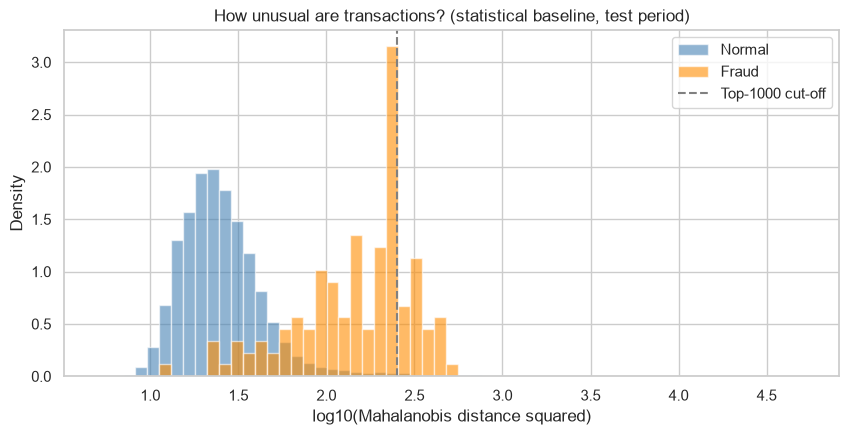

Of the 1,000 most unusual test transactions: 27 are fraud and 973 are legitimate
Legitimate transactions more unusual than the most unusual fraud: 397
Frauds that are less unusual than the median transaction: 2 of 131


In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
b = np.linspace(np.log10(d2_test.min()), np.log10(d2_test.max()), 60)
ax.hist(np.log10(d2_test[y_test == 0]), bins=b, density=True, alpha=0.6, color=NORMAL_COLOUR, label="Normal")
ax.hist(np.log10(d2_test[y_test == 1]), bins=b, density=True, alpha=0.6, color=FRAUD_COLOUR, label="Fraud")
ax.axvline(np.log10(np.sort(d2_test)[-1000]), color="grey", linestyle="--", label="Top-1000 cut-off")
ax.set(title="How unusual are transactions? (statistical baseline, test period)",
       xlabel="log10(Mahalanobis distance squared)", ylabel="Density")
ax.legend()
plt.show()

top1000 = np.argsort(-d2_test)[:1000]          # the 1,000 most unusual test transactions
median_score = np.median(d2_test)
print("Of the 1,000 most unusual test transactions:", y_test[top1000].sum(), "are fraud and",
      1000 - y_test[top1000].sum(), "are legitimate")
print("Legitimate transactions more unusual than the most unusual fraud:",
      (d2_test[y_test == 0] > d2_test[y_test == 1].max()).sum())
print("Frauds that are less unusual than the median transaction:",
      (d2_test[y_test == 1] < median_score).sum(), "of", y_test.sum())

In [18]:
view = test[["Time", "Amount", "Class"]].copy()
view["Mahalanobis d2"] = d2_test
view["Hour"] = ((view["Time"] // 3600) % 24).astype(int)
top = view.iloc[top1000]
print("Median amount (EUR) - unusual but legitimate:", top.loc[top["Class"] == 0, "Amount"].median(),
      "| unusual and fraud:", top.loc[top["Class"] == 1, "Amount"].median(),
      "| all test transactions:", view["Amount"].median())
print("Share of the top 1,000 with Amount above 1,000 EUR:",
      round(100 * (top["Amount"] > 1000).mean(), 1), "%  (all test transactions:",
      round(100 * (view["Amount"] > 1000).mean(), 1), "%)")
print("\nThe 10 most unusual transactions in the test period:")
top.head(10)[["Hour", "Amount", "Mahalanobis d2", "Class"]].round(1)

Median amount (EUR) - unusual but legitimate: 113.3 | unusual and fraud: 1.0 | all test transactions: 22.5
Share of the top 1,000 with Amount above 1,000 EUR: 22.3 %  (all test transactions: 1.1 %)

The 10 most unusual transactions in the test period:


,Hour,Amount,Mahalanobis d2,Class
273745,22,25691.2,51643.8,0
219306,15,5965.0,10457.1,0
219428,15,303.8,10307.1,0
261880,20,1441.1,6741.6,0
218992,15,303.8,6720.8,0
201053,13,1402.4,6646.1,0
218856,15,1417.3,6532.5,0
261876,20,1441.1,6490.2,0
194513,12,4248.3,6458.0,0
216638,15,538.7,6178.4,0


**Evidence from this data:**

- **the most unusual transactions are legitimate.** All of the 10 most unusual test transactions are genuine, including a single purchase of 25,691 EUR. 397 legitimate transactions are more unusual than *any* fraud. In the histogram, the right-hand tail beyond the fraud range contains only normal transactions
- **unusual-but-legitimate transactions tend to be large purchases:** among the top 1,000 most unusual, the median legitimate amount is about 113 EUR, against 22.5 EUR for a typical transaction, and 22% exceed 1,000 EUR (versus 1.1% of all transactions). In contrast, the median *fraud* in the top 1,000 is just 1 EUR
- **of the 1,000 most unusual transactions, 973 are legitimate.** Even though most frauds *are* somewhat unusual (only 2 of 131 are less unusual than the median transaction), the reverse does not hold. Fraud makes up 0.12% of transactions, so even a small share of unusual legitimate transactions vastly outnumbers all the frauds (the *base-rate* effect)

**Why this happens:**

1. **Unusual is a statistical property; fraud is a fact about intent.** An anomaly score measures distance from typical behaviour. Fraud means the cardholder did not authorise the payment. The two overlap, but they are not the same thing (Bolton & Hand, 2002)
2. **Legitimate life is full of rare events:** buying a car part or furniture, travelling abroad, a once-a-year insurance or business payment, a first purchase from a new shop. These are unusual for the population but perfectly genuine
3. **Fraudsters try to look normal.** Card-testing transactions of about 1 EUR, and small purchases below review limits, are designed *not* to stand out. Fraud here sits at *moderate* unusualness, not at the extreme
4. **"Unusual" depends on the reference.** Without customer history, a transaction is compared with *everyone's* behaviour. A 2,000 EUR purchase may be routine for one customer and highly suspicious for another. Unusualness also changes with the features and scaling chosen
5. **The labels themselves are imperfect.** "Fraud" means *confirmed by investigation*. Some unusual transactions labelled normal may be undetected fraud, and some genuine customers dispute real purchases

**Practical consequence:** an anomaly score should be used to **prioritise human review**, not to block cards automatically. Treating every unusual transaction as fraud would decline many genuine purchases, often the large or important ones, and harm customers' trust while still missing fraud designed to look ordinary.

## 10. Conclusions and limitations

**Conclusions**

- with 0.17% fraud, evaluation must focus on the **top of the ranking** (PR-AUC, frauds found per review budget). ROC-AUC alone suggested all methods were nearly equal, which they are not
- the **statistical baseline** (Mahalanobis distance) is 24 times better than random, but its normality assumption fails because of heavy tails, so it is usable only as a ranking
- the **cluster-based** detector (k-means distance) is slightly better than the baseline, but sensitive to *k*, which cannot be tuned without labels
- among **classification-based** approaches, a one-class SVM is the best label-free method, and a **supervised logistic regression is far better** (PR-AUC 0.74; 88% of the top 100 alerts are fraud), because it learns what fraud looks like rather than what is merely unusual
- a combined approach is recommended: supervised ranking as the main queue, label-free scores as a secondary queue for new fraud types, with the cut-off set by investigation capacity

**Limitations**

- **only two days of data from 2013.** Fraud patterns change over time, so models need regular re-training and monitoring
- **only 131 frauds in the test period**, so results carry visible uncertainty (e.g. supervised PR-AUC 0.66–0.82)
- **the PCA transformation was fitted by the data provider on the whole dataset**, including the test period. This is a small, unavoidable source of information leakage that could make all results slightly optimistic
- **anonymised features** mean the models cannot be explained in business terms or audited for unfair treatment of customer groups. A real deployment would need interpretable features and a fairness review
- **duplicates were removed**, although some might be genuine repeated charges
- **hyperparameters** (k, nu, gamma, model settings) used sensible defaults rather than extensive tuning; Section 8 shows the main conclusions do not depend on them

## References

- Bolton, R. J. & Hand, D. J. (2002). Statistical fraud detection: A review. *Statistical Science*, 17(3), 235–255.
- Chandola, V., Banerjee, A. & Kumar, V. (2009). Anomaly detection: A survey. *ACM Computing Surveys*, 41(3), Article 15.
- Dal Pozzolo, A., Caelen, O., Johnson, R. A. & Bontempi, G. (2015). Calibrating probability with undersampling for unbalanced classification. *IEEE Symposium on Computational Intelligence and Data Mining (CIDM)*.
- Han, J., Kamber, M. & Pei, J. (2012). *Data Mining: Concepts and Techniques* (3rd ed.). Morgan Kaufmann. Chapter 12 (outlier detection).
- He, Z., Xu, X. & Deng, S. (2003). Discovering cluster-based local outliers. *Pattern Recognition Letters*, 24(9–10), 1641–1650.
- Mahalanobis, P. C. (1936). On the generalised distance in statistics. *Proceedings of the National Institute of Sciences of India*, 2(1), 49–55.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Saito, T. & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, 10(3), e0118432.
- Schölkopf, B., Platt, J. C., Shawe-Taylor, J., Smola, A. J. & Williamson, R. C. (2001). Estimating the support of a high-dimensional distribution. *Neural Computation*, 13(7), 1443–1471.
- Williams, C. K. I. & Seeger, M. (2001). Using the Nyström method to speed up kernel machines. *Advances in Neural Information Processing Systems 13*, 682–688.